# Figures for the write-up

Every chart in `writeup/` and the README is made here, one cell per figure. All the maths is imported from `pricing.py`; nothing is redefined. Each cell saves a PDF (for LaTeX) and a PNG (for the README) into `writeup/figures/`.

Charts are drawn at the size they print, so the write-up includes them unscaled and the text in them matches the document. The font (TeX Gyre Termes, a free Times New Roman clone) ships in `writeup/fonts/`.

The last cells print every number quoted in the write-up.

Restart and Run All before committing.

In [1]:
import glob
import timeit
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator
from scipy.integrate import quad

from pricing import (
    bs_price,
    centre_and_spread,
    log_price_density,
    price_by_average,
    fingerprint_bs,
    damped_price,
    wound_up,
    price_one_strike,
    price_all_strikes,
)

## the same font as the write-up
for path in glob.glob("writeup/fonts/*.otf"):
    font_manager.fontManager.addfont(path)

## one accent for the data, greys for everything else
INK = "#111827"        ## titles and key numbers
TEXT = "#4B5563"       ## labels and notes
MUTED = "#6B7280"      ## tick labels
GRID = "#E5E7EB"       ## gridlines
BASE = "#C9CED6"       ## baselines and outlines
REFERENCE = "#8A96A3"  ## the exact answer we compare against
ACCENT = "#004225"     ## British racing green: our method / the thing being shown
WASH = "#0042251F"     ## accent at low opacity, for shaded areas
SHADE = LinearSegmentedColormap.from_list("green", ["#FFFFFF", "#D9E6DE", "#7FA68D", "#2C6446", "#00301A"])

plt.rcParams.update({
    "font.family": "TeX Gyre Termes", "font.size": 9.5,
    "mathtext.fontset": "stix",
    "text.color": TEXT,
    "axes.edgecolor": BASE, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.7,
    "axes.labelcolor": TEXT, "axes.labelsize": 9.5,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.titlelocation": "left", "axes.titlepad": 8,
    "xtick.color": BASE, "ytick.color": BASE, "xtick.labelcolor": MUTED, "ytick.labelcolor": MUTED,
    "xtick.major.size": 3, "ytick.major.size": 0, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "lines.linewidth": 1.5, "lines.solid_capstyle": "round",
    "legend.frameon": False, "legend.fontsize": 9, "legend.labelcolor": TEXT,
    "figure.dpi": 150, "savefig.bbox": "tight", "savefig.pad_inches": 0.04, "pdf.fonttype": 42,
})

def save(fig, name):
    fig.savefig(f"writeup/figures/{name}.pdf")
    fig.savefig(f"writeup/figures/{name}.png", dpi=220)

def price_ticks(axis, prices):
    ## a log-price axis, labelled with plain prices
    axis.set_major_locator(FixedLocator(np.log(prices)))
    axis.set_major_formatter(FuncFormatter(lambda x, _: f"{np.exp(x):g}"))
    axis.set_minor_locator(NullLocator())

def callout(ax, x, y, value, note, ha="left"):
    ## a big number with a short note under it
    ax.text(x, y, value, transform=ax.transAxes, ha=ha, va="bottom", fontsize=14.5, fontweight="bold", color=INK)
    ax.text(x, y - 0.02, note, transform=ax.transAxes, ha=ha, va="top", fontsize=9, color=TEXT)

def power_of_ten(x):
    ## 6e-14 written as 6 × 10^-14
    exponent = int(np.floor(np.log10(x)))
    return rf"{x / 10 ** exponent:.0f} × $10^{{{exponent}}}$"

## The running example
S0, K, r, T, vol, a = 100, 100, 0.04, 1.0, 0.20, 1.5
m, spread = centre_and_spread(S0, r, T, vol)
k0 = np.log(K)

## Figure 1: the price is an average

Left: the bell curve of final prices (on a log scale), with the part above the strike shaded: the chance the option pays out. Right: payoff × chance, whose area is the average payoff.

chance it pays out: 0.5398
average payoff:     10.3301
discounted:         9.925054


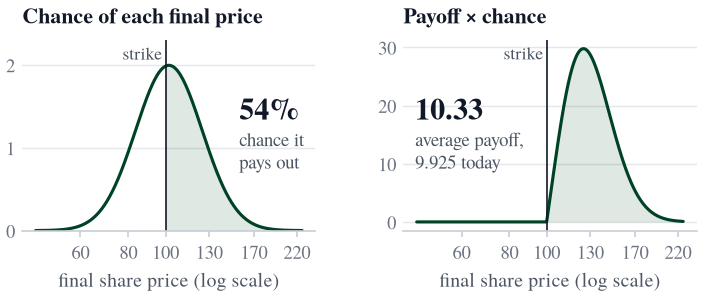

In [2]:
s = np.linspace(m - 4 * spread, m + 4 * spread, 800)
q = log_price_density(s, S0, r, T, vol)
payoff_x_chance = np.maximum(np.exp(s) - K, 0) * q

chance_pays, _ = quad(lambda x: log_price_density(x, S0, r, T, vol), k0, m + 12 * spread)
average_payoff = price_by_average(S0, K, r, T, vol) * np.exp(r * T)   ## undo the discount
print(f"chance it pays out: {chance_pays:.4f}")
print(f"average payoff:     {average_payoff:.4f}")
print(f"discounted:         {average_payoff * np.exp(-r * T):.6f}")

fig, (left, right) = plt.subplots(1, 2, figsize=(5.8, 1.65), gridspec_kw={"wspace": 0.3})

left.fill_between(s, q, where=s >= k0, color=WASH, lw=0)
left.plot(s, q, color=ACCENT)
left.set_title("Chance of each final price")
left.set_ylim(0, 2.3)
left.set_yticks([0, 1, 2])
callout(left, 0.74, 0.55, f"{chance_pays:.0%}", "chance it\npays out")

right.fill_between(s, payoff_x_chance, color=WASH, lw=0)
right.plot(s, payoff_x_chance, color=ACCENT)
right.set_title("Payoff × chance")
right.set_yticks([0, 10, 20, 30])
callout(right, 0.04, 0.55, f"{average_payoff:.2f}", f"average payoff,\n{average_payoff * np.exp(-r * T):.3f} today")

for ax in (left, right):
    ax.axvline(k0, color=INK, lw=0.8)
    ax.text(k0 - 0.02, ax.get_ylim()[1] * 0.97, "strike", ha="right", va="top", fontsize=8.5, color=TEXT)
    price_ticks(ax.xaxis, [60, 80, 100, 130, 170, 220])
    ax.set_xlabel("final share price (log scale)")

save(fig, "price_as_average")
plt.show()

## Figure 2: the fingerprint

Three panels of arrows: each possible log final price turned into an arrow at angle $u \times s$, shaded by how likely it is, with the average arrow (the fingerprint) on top. The last panel is the path of the average arrow as the spin speed runs from 0 to 12.

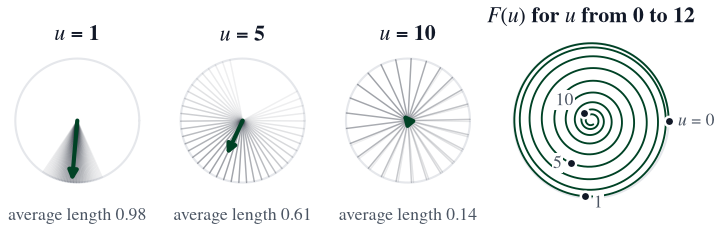

In [3]:
z = np.linspace(-2.5, 2.5, 41)                         ## deviations, in spreads
outcomes = m + spread * z
chance = log_price_density(outcomes, S0, r, T, vol)
chance = chance / chance.max()

circle = np.exp(1j * np.linspace(0, 2 * np.pi, 300))
speeds = [1, 5, 10]

fig = plt.figure(figsize=(5.8, 1.65))
grid = fig.add_gridspec(1, 4, width_ratios=[1, 1, 1, 1.25], wspace=0.15)

def unit_circle(ax):
    ax.plot(circle.real, circle.imag, color=GRID, lw=1)
    ax.set_xlim(-1.15, 1.15)
    ax.set_ylim(-1.15, 1.15)
    ax.set_aspect("equal")
    ax.axis("off")

for i, u in enumerate(speeds):
    ax = fig.add_subplot(grid[i])
    unit_circle(ax)
    for s_i, c in zip(outcomes, chance):
        ax.plot([0, np.cos(u * s_i)], [0, np.sin(u * s_i)], color=INK, alpha=0.05 + 0.35 * c, lw=0.7)
    F = fingerprint_bs(u, S0, r, T, vol)
    ax.annotate("", xy=(F.real, F.imag), xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color=ACCENT, lw=2, mutation_scale=9, shrinkA=0, shrinkB=0))
    ax.set_title(f"$u$ = {u}", loc="center", pad=4)
    ax.text(0, -1.38, f"average length {abs(F):.2f}", ha="center", va="top", fontsize=8.5, color=TEXT)

ax = fig.add_subplot(grid[3])
unit_circle(ax)
u = np.linspace(0, 12, 2000)
F = fingerprint_bs(u, S0, r, T, vol)
ax.plot(F.real, F.imag, color=ACCENT, lw=0.9)
ax.plot(1, 0, "o", color=INK, ms=4.5, mec="white", mew=1.2)
ax.text(1.12, 0, "$u$ = 0", va="center", fontsize=8.5, color=TEXT)
for u_mark, offset in zip(speeds, [(0.12, -0.08), (-0.12, 0), (-0.14, 0.16)]):
    F_mark = fingerprint_bs(u_mark, S0, r, T, vol)
    ax.plot(F_mark.real, F_mark.imag, "o", color=INK, ms=4.5, mec="white", mew=1.2)
    ax.text(F_mark.real + offset[0], F_mark.imag + offset[1], str(u_mark), va="center",
            ha="left" if offset[0] > 0 else "right", fontsize=8.5, color=TEXT,
            bbox=dict(fc="white", ec="none", pad=0.6))
ax.set_title("$F(u)$ for $u$ from 0 to 12", loc="center", pad=4)

save(fig, "fingerprint")
plt.show()

## Figure 3: the round trip

Price world on top, frequency world below. The fingerprint is the only thing taken from the model.

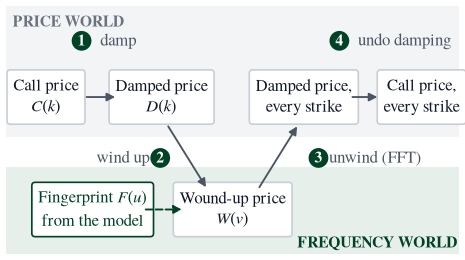

In [4]:
fig, ax = plt.subplots(figsize=(3.9, 2.15))
ax.set_xlim(-0.1, 10.1)
ax.set_ylim(0, 5.3)
ax.axis("off")

## the two worlds
ax.axhspan(2.5, 5.3, color="#F3F4F6", lw=0)
ax.axhspan(0, 1.85, color="#E7EFEA", lw=0)
ax.text(0.05, 5.12, "PRICE WORLD", fontsize=7.5, color=MUTED, va="top", fontweight="bold")
ax.text(10.05, 0.14, "FREQUENCY WORLD", fontsize=7.5, color=ACCENT, ha="right", fontweight="bold")

def node(x, y, label, edge=BASE, colour=INK):
    ax.text(x, y, label, ha="center", va="center", fontsize=8, color=colour, linespacing=1.25,
            bbox=dict(boxstyle="round,pad=0.38,rounding_size=0.2", fc="white", ec=edge, lw=0.8))

node(0.8, 3.35, "Call price\n$C(k)$")
node(3.4, 3.35, "Damped price\n$D(k)$")
node(6.6, 3.35, "Damped price,\nevery strike")
node(9.25, 3.35, "Call price,\nevery strike")
node(5.0, 0.95, "Wound-up price\n$W(v)$")
node(1.85, 0.95, "Fingerprint $F(u)$\nfrom the model", edge=ACCENT, colour=ACCENT)

def step(start, end, number, label, label_at, ha="center", colour=TEXT, ls="-"):
    ax.annotate("", xy=end, xytext=start,
                arrowprops=dict(arrowstyle="-|>", color=colour, lw=0.9, ls=ls, mutation_scale=8))
    if number:
        ax.text(*label_at, f" {number} ", ha=ha, va="center", fontsize=7.5, color="white", fontweight="bold",
                bbox=dict(boxstyle="circle,pad=0.12", fc=ACCENT, ec="none"))
        dx = 0.42 if ha in ("center", "left") else -0.42
        ax.text(label_at[0] + dx, label_at[1], label, ha="left" if dx > 0 else "right", va="center",
                fontsize=8, color=TEXT)

step((1.62, 3.35), (2.45, 3.35), 1, "damp", (1.6, 4.55))
step((3.5, 2.8), (4.45, 1.35), 2, "wind up", (3.55, 2.05), ha="right")
step((5.55, 1.35), (6.5, 2.8), 3, "unwind (FFT)", (6.75, 2.05), ha="left")
step((7.6, 3.35), (8.35, 3.35), 4, "undo damping", (7.4, 4.55))
step((2.95, 0.95), (3.95, 0.95), None, "", (0, 0), colour=ACCENT, ls="--")

save(fig, "round_trip")
plt.show()

## Figure 4: damping

The call price levels off at today's share price for small strikes, so it never dies away on the left. Multiplying by $K^a$ pulls the left end down to zero.

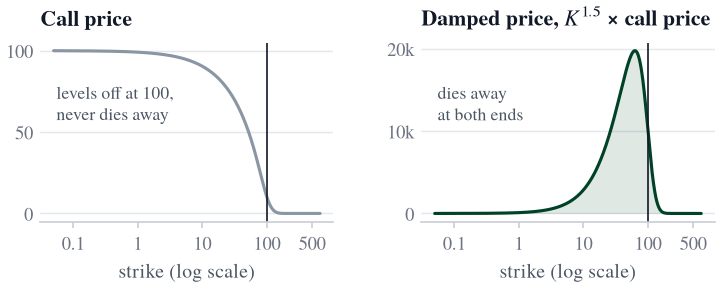

In [5]:
k = np.linspace(-3, 6.5, 800)
call = bs_price(S0, np.exp(k), r, T, vol)
damped = damped_price(S0, np.exp(k), r, T, vol, a)

fig, (left, right) = plt.subplots(1, 2, figsize=(5.8, 1.55), gridspec_kw={"wspace": 0.3})

left.plot(k, call, color=REFERENCE)
left.set_title("Call price")
left.set_yticks([0, 50, 100])
left.text(-2.9, 80, "levels off at 100,\nnever dies away", va="top", fontsize=8.5, color=TEXT)

right.fill_between(k, damped, color=WASH, lw=0)
right.plot(k, damped, color=ACCENT)
right.set_title(f"Damped price, $K^{{{a}}}$ × call price")
right.set_yticks([0, 10000, 20000])
right.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y / 1000:g}k" if y else "0"))
right.text(-2.9, damped.max() * 0.8, "dies away\nat both ends", va="top", fontsize=8.5, color=TEXT)

for ax in (left, right):
    ax.axvline(k0, color=INK, lw=0.8)
    price_ticks(ax.xaxis, [0.1, 1, 10, 100, 500])
    ax.set_xlabel("strike (log scale)")

save(fig, "damping")
plt.show()

## Figure 5: the table, added up by rows and by columns

Each cell is discount × chance of the outcome × damping × payoff, at spin speed $v = 0$. Outcomes run across, strikes run down. Above the diagonal the outcome is below the strike, so the payoff is zero.

- **Rows** add up to the damped price at each strike (what `damped_price` gives).
- **Columns** add up to one outcome's contribution, which has a formula that needs only the payoff and the chance.
- Both grand totals match `wound_up(0)`.

total by rows:    30,520.88
total by columns: 30,520.88
wound_up(0):      30,520.98


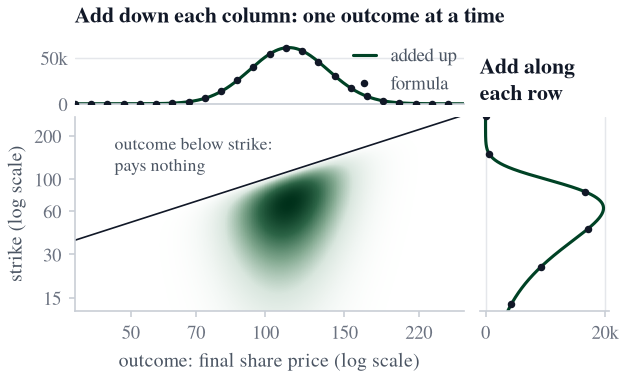

In [6]:
s = np.linspace(m - 5 * spread, m + 5 * spread, 600)
k = np.linspace(-10, 6, 4000)
S, Kg = np.meshgrid(s, k)

## each cell: discount x chance of the outcome x damping x payoff
cells = (np.exp(-r * T) * log_price_density(S, S0, r, T, vol)
         * np.exp(a * Kg) * np.maximum(np.exp(S) - np.exp(Kg), 0))

row_totals = np.trapezoid(cells, s, axis=1)   ## Way 1: the damped price at each strike
col_totals = np.trapezoid(cells, k, axis=0)   ## Way 2: one outcome's contribution

row_formula = damped_price(S0, np.exp(k), r, T, vol, a)
col_formula = (np.exp(-r * T) * log_price_density(s, S0, r, T, vol)
               * np.exp((a + 1) * s) / (a ** 2 + a))   ## the Step 6 formula at v = 0

by_rows = np.trapezoid(row_totals, k)
by_columns = np.trapezoid(col_totals, s)
print(f"total by rows:    {by_rows:,.2f}")
print(f"total by columns: {by_columns:,.2f}")
print(f"wound_up(0):      {wound_up(0, S0, r, T, vol, a).real:,.2f}")

fig = plt.figure(figsize=(4.6, 2.35))
grid = fig.add_gridspec(2, 2, width_ratios=[3, 1], height_ratios=[1, 3], wspace=0.06, hspace=0.1)
ax = fig.add_subplot(grid[1, 0])
top = fig.add_subplot(grid[0, 0], sharex=ax)
right = fig.add_subplot(grid[1, 1], sharey=ax)

ax.pcolormesh(s, k, cells, shading="auto", cmap=SHADE, rasterized=True)
ax.plot(s, s, color=INK, lw=0.8)
ax.text(np.log(46), np.log(205), "outcome below strike:\npays nothing", fontsize=8.5, color=TEXT, va="top")
ax.grid(False)
ax.spines["left"].set_visible(True)
ax.set_xlabel("outcome: final share price (log scale)")
ax.set_ylabel("strike (log scale)")
ax.set_ylim(2.5, 5.6)
price_ticks(ax.xaxis, [50, 70, 100, 150, 220])
price_ticks(ax.yaxis, [15, 30, 60, 100, 200])
ax.tick_params(axis="y", length=3)

every = 25   ## show the formula as dots, so the added-up line underneath stays visible
top.plot(s, col_totals, color=ACCENT, label="added up")
top.plot(s[::every], col_formula[::every], "o", color=INK, ms=2.6, label="formula", zorder=3)
top.set_title("Add down each column: one outcome at a time")
top.set_ylim(0, col_totals.max() * 1.15)
top.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y / 1000:g}k" if y else "0"))
top.legend(loc="upper right", handlelength=1.2, borderaxespad=0)
plt.setp(top.get_xticklabels(), visible=False)
top.tick_params(axis="x", length=0)

right.plot(row_totals, k, color=ACCENT)
right.plot(row_formula[::every * 6], k[::every * 6], "o", color=INK, ms=2.6, zorder=3)
right.set_title("Add along\neach row", loc="left")
right.grid(axis="x")
right.grid(axis="y", visible=False)
right.set_xticks([0, 20000])
right.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x / 1000:g}k" if x else "0"))
plt.setp(right.get_yticklabels(), visible=False)

save(fig, "table")
plt.show()

## Figure 6 (notebook only): the slices being unwound

The slices $\text{Re}[e^{-ivk}W(v)]$ for strike 100. They die away by about $v = 4$, which is why the integral can stop early.

area under the slices: 31,180.5
undo damping and divide by pi: 9.925054


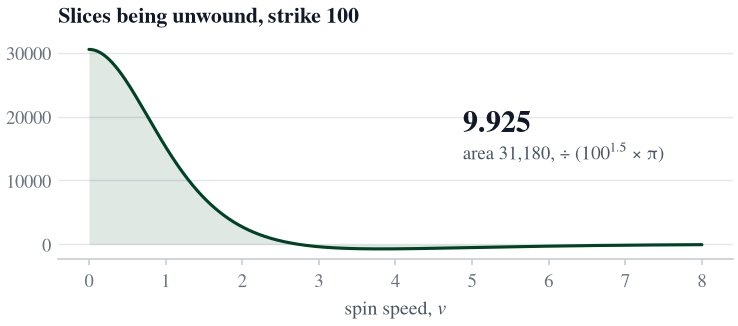

In [7]:
v = np.linspace(0, 8, 1000)
slices = (np.exp(-1j * v * k0) * wound_up(v, S0, r, T, vol, a)).real
area, _ = quad(lambda x: (np.exp(-1j * x * k0) * wound_up(x, S0, r, T, vol, a)).real, 0, 200, limit=500)
print(f"area under the slices: {area:,.1f}")
print(f"undo damping and divide by pi: {area / (K ** a * np.pi):.6f}")

fig, ax = plt.subplots(figsize=(5.8, 1.9))
ax.fill_between(v, slices, color=WASH, lw=0)
ax.plot(v, slices, color=ACCENT)
ax.set_title("Slices being unwound, strike 100")
ax.set_xlabel("spin speed, $v$")
callout(ax, 0.6, 0.55, f"{area / (K ** a * np.pi):.3f}", f"area {area:,.0f}, ÷ ($100^{{1.5}}$ × π)")
save(fig, "unwind_slices")
plt.show()

## Figure 7: FFT accuracy (headline)

One call to `price_all_strikes` against the Black-Scholes formula, for every grid strike between 50 and 200.

4096 strikes priced; 225 between 50 and 200
largest gap from Black-Scholes, strikes 50 to 200: 6.0e-14


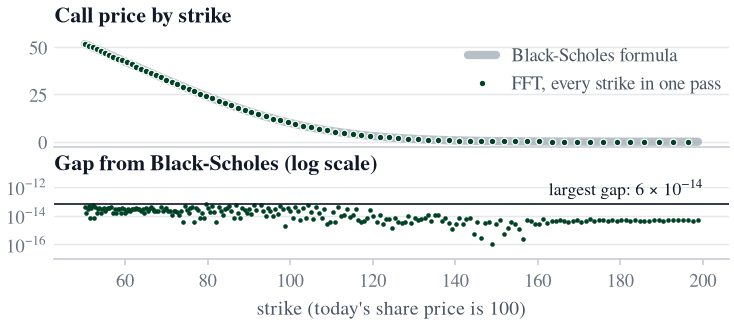

In [8]:
strikes, prices = price_all_strikes(S0, r, T, vol, damping=a)
shown = (strikes >= 50) & (strikes <= 200)
exact = bs_price(S0, strikes[shown], r, T, vol)
gap = np.abs(prices[shown] - exact)
print(f"{len(strikes)} strikes priced; {shown.sum()} between 50 and 200")
print(f"largest gap from Black-Scholes, strikes 50 to 200: {gap.max():.1e}")

fig, (upper, lower) = plt.subplots(2, 1, figsize=(5.8, 1.9), sharex=True, height_ratios=[1.5, 1],
                                   gridspec_kw={"hspace": 0.45})

upper.plot(strikes[shown], exact, color=REFERENCE, lw=4, alpha=0.6, label="Black-Scholes formula")
upper.plot(strikes[shown][::3], prices[shown][::3], "o", color=ACCENT, ms=3.2, mec="white", mew=0.6,
           label="FFT, every strike in one pass")
upper.set_title("Call price by strike")
upper.set_yticks([0, 25, 50])
upper.legend(loc="upper right", handlelength=1.5, borderaxespad=0)
upper.tick_params(axis="x", length=0)

exact_match = gap == 0   ## a gap of exactly zero can't go on a log scale, so leave it off
lower.semilogy(strikes[shown][~exact_match], gap[~exact_match], "o", color=ACCENT, ms=2.2, mew=0)
lower.axhline(gap.max(), color=INK, lw=0.8)
lower.text(200, gap.max() * 2.2, f"largest gap: {power_of_ten(gap.max())}", ha="right", va="bottom",
           fontsize=8.5, color=INK)
lower.set_ylim(1e-17, 1e-12)
lower.set_yticks([1e-16, 1e-14, 1e-12])
lower.minorticks_off()
lower.set_title("Gap from Black-Scholes (log scale)")
lower.set_xlabel("strike (today's share price is 100)")

save(fig, "fft_accuracy")
plt.show()

## Numbers for the write-up

Every number quoted in the write-up and README that isn't printed above. Timings depend on the machine; these are from a laptop.

In [9]:
## The 3-outcome, 3-strike table (Section 6), before the arrows. Discounting left out.
outcome_prices = np.array([80, 100, 120])
outcome_chances = np.array([0.25, 0.5, 0.25])
small_strikes = np.array([70, 90, 110])
small_table = (outcome_chances[None, :] * small_strikes[:, None] ** a
               * np.maximum(outcome_prices[None, :] - small_strikes[:, None], 0))
print("small table:\n", small_table.round(0))
print("row totals:   ", small_table.sum(axis=1).round(0))
print("column totals:", small_table.sum(axis=0).round(0))
arrows = np.exp(1j * 2 * np.log(small_strikes))
print(f"grand total with arrows at v = 2: {(small_table * arrows[:, None]).sum():,.0f}")

small table:
 [[1464. 8785. 7321.]
 [   0. 4269. 6404.]
 [   0.    0. 2884.]]
row totals:    [17570. 10673.  2884.]
column totals: [ 1464. 13054. 16609.]
grand total with arrows at v = 2: -23,141+18,532j


In [10]:
## Single strikes by Fourier inversion (Step 7)
for strike in [80, 100, 120]:
    print(f"strike {strike}: one strike {price_one_strike(S0, strike, r, T, vol):.6f}, "
          f"Black-Scholes {bs_price(S0, strike, r, T, vol):.6f}")

## Timing: best of several runs
def best_time(f, number=200):
    return min(timeit.repeat(f, number=number, repeat=7)) / number

fft_time = best_time(lambda: price_all_strikes(S0, r, T, vol))
one_strike_time = best_time(lambda: price_one_strike(S0, K, r, T, vol))
N = len(strikes)
print(f"\nFFT, all {N} strikes: {fft_time * 1e3:.2f} ms")
print(f"quad, one strike:     {one_strike_time * 1e3:.2f} ms")
print(f"quad, all {N} strikes (one at a time): {N * one_strike_time:.1f} s")
print(f"speed-up for the full grid: about {N * one_strike_time / fft_time:,.0f} times")
print(f"steps: one sum per strike {N * N:,}, FFT about {N * int(np.log2(N)):,}")

strike 80: one strike 23.906164, Black-Scholes 23.906164
strike 100: one strike 9.925054, Black-Scholes 9.925054
strike 120: one strike 2.999949, Black-Scholes 2.999949



FFT, all 4096 strikes: 0.22 ms
quad, one strike:     0.53 ms
quad, all 4096 strikes (one at a time): 2.2 s
speed-up for the full grid: about 9,778 times
steps: one sum per strike 16,777,216, FFT about 49,152


In [11]:
## Limits: how damping strength and grid spacing affect accuracy
def worst_gap(low, high, **settings):
    strikes, prices = price_all_strikes(S0, r, T, vol, **settings)
    inside = (strikes >= low) & (strikes <= high)
    return np.max(np.abs(prices[inside] - bs_price(S0, strikes[inside], r, T, vol)))

print("damping   strikes 1-10   strikes 50-200")
for damping in [0.5, 1.0, 1.5, 3.0, 5.0]:
    print(f"{damping:>7}   {worst_gap(1, 10, damping=damping):.1e}        {worst_gap(50, 200, damping=damping):.1e}")

print("\nspin spacing   strike spacing   strikes 50-200")
for spin_spacing in [0.25, 1.0]:
    strike_spacing = 2 * np.pi / (4096 * spin_spacing)
    print(f"{spin_spacing:>12}   {strike_spacing:.4f} ({np.exp(strike_spacing) - 1:.2%} apart)   "
          f"{worst_gap(50, 200, spin_spacing=spin_spacing):.1e}")

damping   strikes 1-10   strikes 50-200
    0.5   3.5e-04        3.5e-04
    1.0   1.2e-09        1.2e-09
    1.5   1.9e-12        6.0e-14
    3.0   2.6e-09        1.1e-13
    5.0   4.0e-05        3.0e-13

spin spacing   strike spacing   strikes 50-200
        0.25   0.0061 (0.62% apart)   6.0e-14
         1.0   0.0015 (0.15% apart)   8.1e-03
